# Week 6: Which comparison are we creating?

**Central question:** when we add a control, or keep only some rows, what comparison have we created?

By the end you should be able to:

1. Explain why we control for a confounder but not for a mediator or a collider.
2. Explain how adding a control can change the *question being answered*, not just the number.
3. Explain why conditioning on a collider creates a misleading association, and when it can be repaired.
4. Explain what a causal diagram tells us (what to control for) and what it doesn't (the equation).

| Part | Topic | Treatment |
|---|---|---|
| 1 | Does the school's diagram need practice? | tutoring (joined or not) |
| 2 | Controlling for practice changes the question | tutoring (joined or not) |
| 3 | Interactions: what is "the effect"? | tutoring (joined or not) |
| 4 | Colliders: when controlling creates a problem | tutoring hours |
| 5 | Diagrams and equations are not one-to-one | tutoring hours |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.special import expit
from statsmodels.formula.api import ols

BLUE, ORANGE, GREY = "#1B5AA6", "#D9822B", "#999999"


def draw_dags(panels, figsize=None):
    """Draw diagrams side by side. Each panel: dict(title, edges, pos, boxed=(), highlight=())."""
    fig, axes = plt.subplots(1, len(panels), figsize=figsize or (5.2 * len(panels), 3.2))
    for ax, p in zip(np.atleast_1d(axes), panels):
        G = nx.DiGraph(p["edges"])
        G.add_nodes_from(p["pos"])
        highlight = set(p.get("highlight", ()))
        for edges, color, width in [([e for e in G.edges if e not in highlight], "#333333", 1.8),
                                    (list(highlight), ORANGE, 3)]:
            nx.draw_networkx_edges(G, p["pos"], edgelist=edges, ax=ax, arrowstyle="-|>",
                                   arrowsize=16, width=width, node_size=4200, edge_color=color)
        for node, (x, y) in p["pos"].items():
            boxed = node in p.get("boxed", ())
            ax.text(x, y, node, ha="center", va="center", fontsize=10,
                    bbox=dict(boxstyle="round,pad=0.4", fc="#FFF4E0" if boxed else "#D9EAF7",
                              ec=BLUE if boxed else "black", lw=2.5 if boxed else 1))
        ax.set_title(p["title"], fontsize=11)
        ax.margins(0.22)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def ci(m, term):
    """(estimate, lower, upper) for one coefficient."""
    lo, hi = m.conf_int().loc[term]
    return m.params[term], lo, hi


def coef_plot(rows, truths, title, xlabel="estimated effect"):
    """rows: list of (label, estimate, lower, upper). truths: {label: value} drawn as dashed lines."""
    fig, ax = plt.subplots(figsize=(7.5, 0.6 * len(rows) + 1.6))
    for i, (label, est, lo, hi) in enumerate(rows):
        ax.errorbar(est, i, xerr=[[est - lo], [hi - est]], fmt="o", color=BLUE, capsize=4, ms=7)
        ax.text(est, i - 0.22, f"{est:.2f}", ha="center", fontsize=10)
    for (label, value), color in zip(truths.items(), [ORANGE, GREY]):
        ax.axvline(value, color=color, ls="--", lw=2)
        ax.text(value, -0.75, f"{label} = {value:g}", color=color, ha="center", fontsize=9)
    xs = [v for r in rows for v in r[2:]] + list(truths.values())
    pad = 0.12 * (max(xs) - min(xs))
    ax.set_xlim(min(xs) - pad, max(xs) + pad)
    ax.set_ylim(len(rows) - 0.5, -1.0)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows])
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# Same variable, same place, in every diagram of Parts 1-3
POS = {"Preparedness": (1, 2.4), "Tutoring": (0, 0), "Exam score": (2, 0), "Practice": (1, 0.8)}
POS3 = {k: POS[k] for k in ["Preparedness", "Tutoring", "Exam score"]}
FULL_EDGES = [("Preparedness", "Tutoring"), ("Preparedness", "Exam score"),
              ("Preparedness", "Practice"), ("Tutoring", "Practice"),
              ("Practice", "Exam score"), ("Tutoring", "Exam score")]
SCHOOL_EDGES = [("Preparedness", "Tutoring"), ("Preparedness", "Exam score"),
                ("Tutoring", "Exam score")]
n = 4000

---
## Part 1: Does the school's diagram need practice?

**The question:** how much does tutoring change final exam scores?

- We want the **total effect**: every way tutoring changes scores
- Including any extra practice that tutoring leads to

**The data** (4,000 students):

| Column | Meaning | Measured |
|---|---|---|
| `preparedness` | readiness for the course (0 = district average, 1 = one standard deviation above) | before tutoring |
| `tutoring` | 1 = joined tutoring, 0 = did not (the slides' "tutoring participation") | start of term |
| `practice` | practice index: higher = more practice completed; most students fall between 3 and 9 | after tutoring begins |
| `exam_score` | final exam score | end of term |

In [2]:
rng = np.random.default_rng(2025)
preparedness = rng.normal(0, 1, n)
tutoring = rng.binomial(1, expit(-0.8 * preparedness))   # less-prepared students join more
practice = 5 + 2 * tutoring + 0.5 * preparedness + rng.normal(0, 1, n)
exam_score = 60 + 2 * tutoring + 2 * practice + 6 * preparedness + rng.normal(0, 4, n)

school = pd.DataFrame({"preparedness": preparedness, "tutoring": tutoring,
                       "practice": practice, "exam_score": exam_score})
school.head()

,preparedness,tutoring,practice,exam_score
0,-2.221254,0,4.226919,58.126894
1,0.026000,0,4.087892,68.893379
2,-0.538969,1,6.387200,68.396317
3,-1.129193,1,7.427636,73.577493
4,-2.441867,1,4.491961,54.025125


### Two diagrams

- **Assumed:** the school's story from the slides. Practice is left out.
- **Actual:** the story that generated the data. We know it only because we wrote the simulation.
- In a real study, you never see the actual diagram.

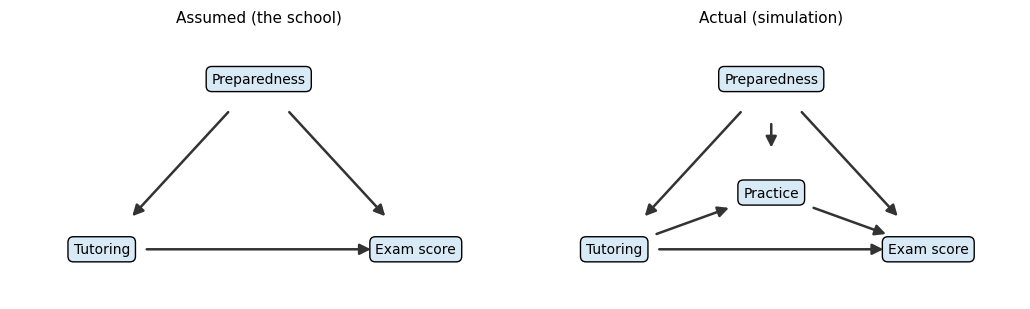

In [3]:
draw_dags([dict(title="Assumed (the school)", edges=SCHOOL_EDGES, pos=POS3),
           dict(title="Actual (simulation)", edges=FULL_EDGES, pos=POS)])

### The true total effect

From the simulation code (T = tutoring, P = preparedness):

- practice $= 5 + 2\,T + 0.5\,P + \text{noise}$
- score $= 60 + 2\,T + 2\cdot\text{practice} + 6\,P + \text{noise}$

Substitute practice into score:

$$\text{score} = 70 + \underbrace{6}_{2 + 2\times 2}\,T + 7\,P + \text{noise}$$

- 2 points directly
- 4 points through practice (+2 practice × 2 points each)
- **Total effect = 6**

### Discussion

Work through the **actual** diagram step by step:

1. List every path from tutoring to score (arrows can point either way along a path).
2. Which paths **start with an arrow out of** tutoring? These carry tutoring's effect.
3. Which paths **start with an arrow into** tutoring? These are backdoor paths. They must be blocked.
4. Now look at the **assumed** diagram. Does it lead to the same controls?

**Answers**

| Path | Type | Action |
|---|---|---|
| tutoring → score | effect (Q2) | keep |
| tutoring → practice → score | effect (Q2) | keep |
| tutoring ← preparedness → score | backdoor (Q3) | control preparedness |
| tutoring ← preparedness → practice → score | backdoor (Q3) | control preparedness |
| tutoring → practice ← preparedness → score | already blocked (two arrows meet at practice) | leave it; see Part 2 |

- Q4: **yes.** Both diagrams say: control for preparedness, nothing else.
- The school's single tutoring → score arrow stands for *both* effect paths.

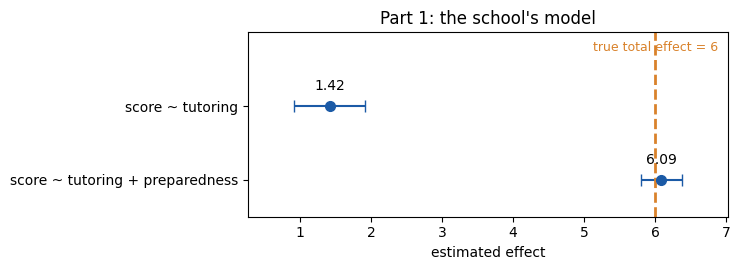

In [4]:
m_none = ols("exam_score ~ tutoring", data=school).fit()
m_school = ols("exam_score ~ tutoring + preparedness", data=school).fit()

coef_plot([("score ~ tutoring", *ci(m_none, "tutoring")),
           ("score ~ tutoring + preparedness", *ci(m_school, "tutoring"))],
          {"true total effect": 6}, "Part 1: the school's model")

**Takeaways**

- The school's diagram recovers the total effect, even without practice
- Leaving a **mediator** out of the diagram: harmless for the total effect
- Leaving a **confounder** out (e.g. motivation): not harmless. A backdoor path would be missed.
- The school's diagram *can't* answer "how much works through practice?" It has no practice node.

---
## Part 2: Controlling for practice changes the question

A colleague: *"Practice is in the data and it predicts scores. Let's control for it too."*

- Same school, same data as Part 1
- The colleague uses the actual diagram
- Boxed = controlled for

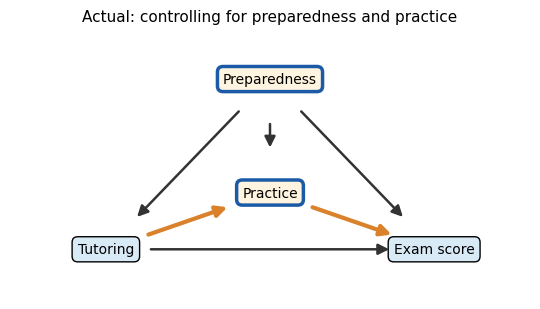

In [5]:
draw_dags([dict(title="Actual: controlling for preparedness and practice", edges=FULL_EDGES, pos=POS,
                boxed={"Preparedness", "Practice"},
                highlight={("Tutoring", "Practice"), ("Practice", "Exam score")})],
          figsize=(5.5, 3.2))

### Discussion

1. Which of Part 1's effect paths go through practice? (orange)
2. If we compare students with the **same** practice, can tutoring still raise scores through practice?
3. So which part of the 6 points is left?

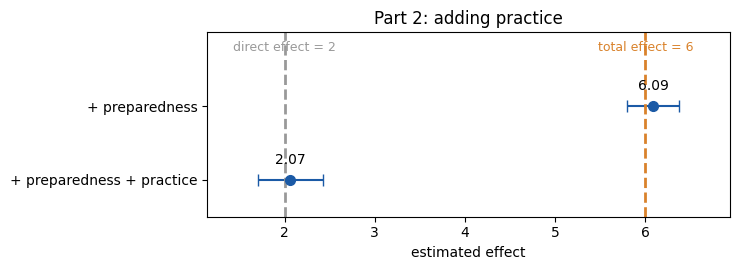

residual SD: 4.45 (without practice) vs 3.98 (with practice)


In [6]:
m_practice = ols("exam_score ~ tutoring + preparedness + practice", data=school).fit()

coef_plot([("+ preparedness", *ci(m_school, "tutoring")),
           ("+ preparedness + practice", *ci(m_practice, "tutoring"))],
          {"total effect": 6, "direct effect": 2}, "Part 2: adding practice")

print(f"residual SD: {np.sqrt(m_school.mse_resid):.2f} (without practice) vs "
      f"{np.sqrt(m_practice.mse_resid):.2f} (with practice)")

**Answers**

1. tutoring → practice → score
2. No. Practice is held equal, so that route is shut off.
3. Only the direct part: **≈ 2**

- The first model wasn't biased. **We changed the question.**
- The model with practice fits better (smaller residual SD), yet it answers a different question

$$\underbrace{6}_{\text{total}} = \underbrace{2}_{\text{direct}} + \underbrace{2 \times 2}_{\text{through practice}}$$

### Step up: what if we control for practice but forget preparedness?

Look at practice in the actual diagram:

- Arrows **into** practice: from tutoring **and** from preparedness
- Two arrows in → practice is also a **collider** on: tutoring → practice ← preparedness → score
- That path is blocked... until we control for practice

**Discussion:**

1. With `score ~ tutoring + practice`, which paths are open?
2. Take a tutored and an untutored student with the **same** practice. Who is likely more prepared?

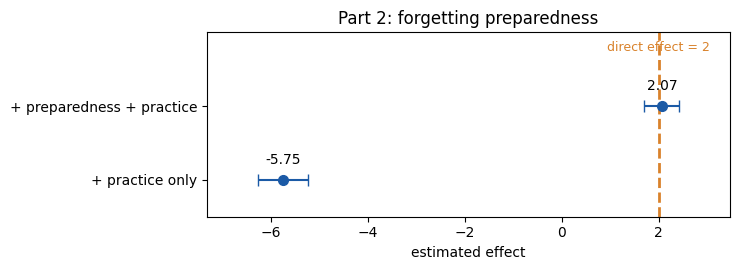

In [7]:
m_forget = ols("exam_score ~ tutoring + practice", data=school).fit()

coef_plot([("+ preparedness + practice", *ci(m_practice, "tutoring")),
           ("+ practice only", *ci(m_forget, "tutoring"))],
          {"direct effect": 2}, "Part 2: forgetting preparedness")

**Answers**

1. Two open paths:
    - tutoring ← preparedness → score (backdoor, never blocked)
    - tutoring → practice ← preparedness → score (opened by controlling for the collider)
2. The **untutored** student:
    - Ana (tutored) and Ben (not tutored) did the same practice
    - Tutoring pushed Ana's practice up; Ben got there without it
    - So Ben is likely the more prepared one → Ben scores higher → tutoring looks harmful

**Controlling for preparedness blocks both paths.** That's why the previous model got 2.

We'll come back to colliders in Part 4.

---
## Part 3: Interactions: what is "the effect"?

**New schools** (not the Part 1–2 school):

- Same three variables: preparedness, tutoring, score (no practice)
- Each school may decide differently **who gets tutoring**
- Preparedness is on the same district-wide scale (0 = district average)

One change in the score equation: **tutoring helps less-prepared students more.**

$$\text{score} = 70 + (4 - 2\cdot\text{preparedness})\cdot\text{tutoring} + 6\cdot\text{preparedness} + \text{noise}$$

| preparedness | effect of tutoring |
|---|---|
| −1 | 6 |
| 0 | 4 |
| +1 | 2 |

### Discussion

The equation multiplies tutoring **by** preparedness.

1. Should the diagram get an arrow between tutoring and preparedness?
2. Hint: an arrow A → B means "changing A changes B." Does preparedness change who gets tutoring?
3. Can you answer question 2 from the score equation alone?

**Answers**

1. It depends on how students get tutoring, **not** on the equation:
    - **Lottery school:** seats assigned by lottery → preparedness doesn't affect who joins → **no arrow**
    - **Selective school:** advisors push less-prepared students → **arrow** preparedness → tutoring
2. Lottery school: no. Selective school: yes.
3. **No.** Both schools use the *same* score equation.

- The interaction lives *inside* the score equation: two arrows into score. Diagrams can't show the multiplication.
- In both schools the analyst's assumed diagram matches the actual one

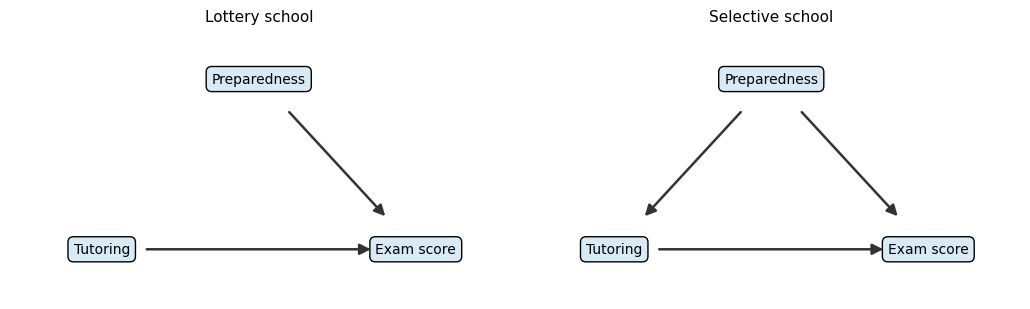

In [8]:
draw_dags([dict(title="Lottery school", pos=POS3,
                edges=[("Preparedness", "Exam score"), ("Tutoring", "Exam score")]),
           dict(title="Selective school", pos=POS3, edges=SCHOOL_EDGES)])

### Why we need to define "the effect"

- Linear model `score = a + b·tutoring + c·preparedness`: the effect is **b**, the same for every student
- Here the effect is **4 − 2·preparedness**: a different number for each student
- To report one number, we must **choose** one:
    - The effect for a student with preparedness 0?
    - The effect for a typical student *in this school*?
- We use the **average effect across the school's students**:

$$\text{average effect} = \text{mean over students of } (4 - 2\cdot\text{preparedness}_i) = 4 - 2\cdot\overline{\text{preparedness}}$$

Both new schools are **above** the district: their students average preparedness = 1.

- So the effect at preparedness 0 (= 4) is **not** the effect for a typical student here (= 2)

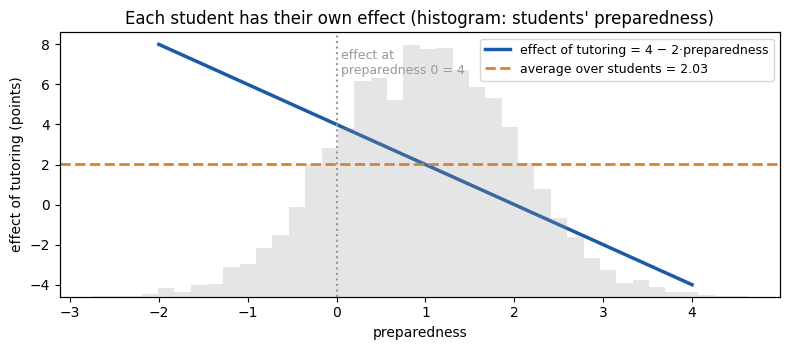

In [9]:
rng = np.random.default_rng(2026)
p_lot = rng.normal(1, 1, n)
t_lot = rng.binomial(1, 0.5, n)                                   # lottery
y_lot = 70 + (4 - 2 * p_lot) * t_lot + 6 * p_lot + rng.normal(0, 4, n)
lottery_school = pd.DataFrame({"preparedness": p_lot, "tutoring": t_lot, "exam_score": y_lot})

p_sel = rng.normal(1, 1, n)
t_sel = rng.binomial(1, expit(-1.5 * p_sel))                      # less-prepared students pushed to join
y_sel = 70 + (4 - 2 * p_sel) * t_sel + 6 * p_sel + rng.normal(0, 4, n)
selective_school = pd.DataFrame({"preparedness": p_sel, "tutoring": t_sel, "exam_score": y_sel})

avg_lot = (4 - 2 * p_lot).mean()
avg_sel = (4 - 2 * p_sel).mean()

fig, ax = plt.subplots(figsize=(8, 3.6))
grid = np.linspace(-2, 4, 100)
ax.plot(grid, 4 - 2 * grid, color=BLUE, lw=2.5, label="effect of tutoring = 4 − 2·preparedness")
ax.axhline(avg_lot, color=ORANGE, ls="--", lw=2, label=f"average over students = {avg_lot:.2f}")
ax.axvline(0, color=GREY, ls=":", lw=1.5)
ax.text(0.05, 6.5, "effect at\npreparedness 0 = 4", color=GREY, fontsize=9)
ax.set_xlabel("preparedness")
ax.set_ylabel("effect of tutoring (points)")
ax2 = ax.twinx()
ax2.hist(p_lot, bins=40, color=GREY, alpha=0.25)
ax2.set_yticks([])
ax.legend(loc="upper right", fontsize=9)
ax.set_title("Each student has their own effect (histogram: students' preparedness)")
plt.tight_layout()
plt.show()

### Case A: interaction, no arrow (lottery school)

**Discussion:** we fit `score ~ tutoring`. It ignores preparedness and the interaction.

1. Is the comparison fair? (Who ends up in each group?)
2. If both groups have the same mix of students, what does the difference in their average scores measure?

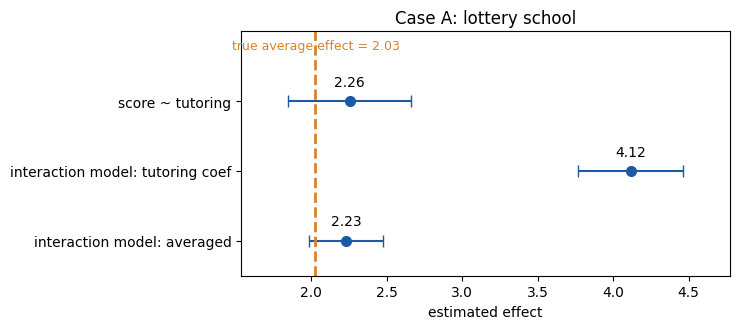

In [10]:
m_simple = ols("exam_score ~ tutoring", data=lottery_school).fit()
m_inter = ols("exam_score ~ tutoring * preparedness", data=lottery_school).fit()


def average_effect(m, df):
    """b + e * mean(preparedness), with its 95% CI."""
    weights = pd.Series(0.0, index=m.params.index)
    weights["tutoring"] = 1
    weights["tutoring:preparedness"] = df["preparedness"].mean()
    test = m.t_test(weights.values)
    lo, hi = test.conf_int()[0]
    return test.effect[0], lo, hi


coef_plot([("score ~ tutoring", *ci(m_simple, "tutoring")),
           ("interaction model: tutoring coef", *ci(m_inter, "tutoring")),
           ("interaction model: averaged", *average_effect(m_inter, lottery_school))],
          {"true average effect": round(avg_lot, 2)}, "Case A: lottery school")

**Answers**

1. **Yes.** The lottery gives both groups the same mix of preparedness.
2. The **average effect**: each student's effect, averaged over the school.

- **Simple model ≈ average effect**, even though it ignores the interaction
- **Interaction coefficient ≈ 4.** That is the effect at preparedness 0, a rare student in this school.
- **Interaction model, averaged** (b + e·mean preparedness) ≈ average effect, *plus* it shows how the effect varies

| Model | Gives | Misses |
|---|---|---|
| `score ~ tutoring` | average effect | how the effect varies |
| `score ~ tutoring * preparedness` | effect at every preparedness level | nothing, but its coefficient alone ≠ average effect |

Another way to average, which works for any model: predict every student with tutoring = 1 and = 0, subtract, average.

In [11]:
pred_1 = m_inter.predict(lottery_school.assign(tutoring=1))
pred_0 = m_inter.predict(lottery_school.assign(tutoring=0))
print(f"average of predicted differences = {(pred_1 - pred_0).mean():.2f}")

average of predicted differences = 2.23


### Case B: interaction **and** an arrow (selective school)

Now less-prepared students are pushed to join.

**Discussion:**

1. Who is in the tutoring group now: more or less prepared students?
2. Is `score ~ tutoring` still a fair comparison?
3. Which models below get the average effect?

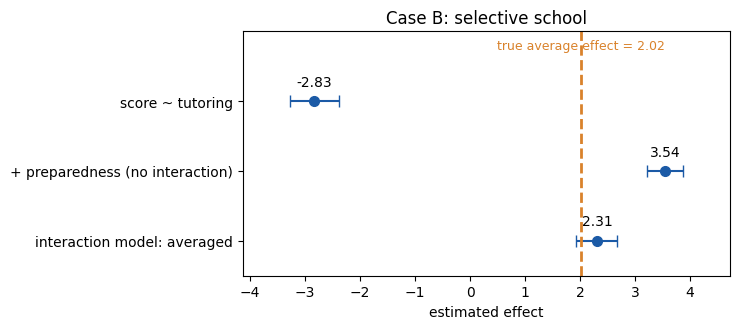

In [12]:
s_simple = ols("exam_score ~ tutoring", data=selective_school).fit()
s_add = ols("exam_score ~ tutoring + preparedness", data=selective_school).fit()
s_inter = ols("exam_score ~ tutoring * preparedness", data=selective_school).fit()

coef_plot([("score ~ tutoring", *ci(s_simple, "tutoring")),
           ("+ preparedness (no interaction)", *ci(s_add, "tutoring")),
           ("interaction model: averaged", *average_effect(s_inter, selective_school))],
          {"true average effect": round(avg_sel, 2)}, "Case B: selective school")

**Answers**

1. **Less** prepared students
2. **No.** Tutored students would score lower even without tutoring (backdoor path through preparedness). The simple model is badly biased.
3. Only the **interaction model, averaged**

- **+ preparedness, no interaction: off.** It blocks the backdoor path, but forces one effect for everyone. That single effect leans toward less-prepared students (where both groups overlap most), not the school's average.

**Takeaways**

- An interaction does **not** add an arrow. Arrows come from what causes what.
- The diagram says *what to control for* (preparedness, in Case B)
- It doesn't say *how* (with or without the interaction). That's a modeling choice.
- With an interaction, "the effect" must be defined. We use the average over students.

---
## Part 4: Colliders: when controlling creates a problem

**A new randomized pilot. Three things are new:**

1. **`tutoring_hours`** (replaces joined / not joined)
    - 0 to 5 hours per week, assigned by lottery
    - Effects are straight lines → the coefficient is the effect **per extra hour**, the same for everyone
2. **`motivation`**: from a survey before the pilot (0 = average)
3. **`study_group`**: 1 = joined an optional study group
    - Tutors recommend the group in their sessions → **more tutoring hours, more likely to join**
    - Motivated students join on their own → **more motivation, more likely to join**
    - Assume joining doesn't change exam scores

`exam_score`: true effect = **+2 points per hour**. Motivation also raises scores.

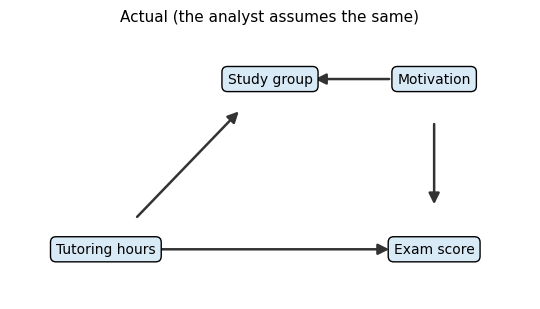

In [13]:
rng = np.random.default_rng(2027)
tutoring_hours = rng.uniform(0, 5, n)                                          # lottery
motivation = rng.normal(0, 1, n)
study_group = rng.binomial(1, expit(-6 + 2 * tutoring_hours + 3 * motivation))
exam_score = 60 + 2 * tutoring_hours + 10 * motivation + rng.normal(0, 4, n)

pilot = pd.DataFrame({"tutoring_hours": tutoring_hours, "motivation": motivation,
                      "study_group": study_group, "exam_score": exam_score})

POS4 = {"Tutoring hours": (0, 0), "Exam score": (2, 0), "Study group": (1, 1.4), "Motivation": (2, 1.4)}
PILOT_EDGES = [("Tutoring hours", "Exam score"), ("Motivation", "Exam score"),
               ("Tutoring hours", "Study group"), ("Motivation", "Study group")]
draw_dags([dict(title="Actual (the analyst assumes the same)", edges=PILOT_EDGES, pos=POS4)],
          figsize=(5.5, 3.2))

### Discussion

1. Across **all** students: are tutoring hours and motivation related? (How were hours assigned?)
2. Now look **only at study-group members**. Pick a member with very few tutoring hours.
    - Why did they join?
3. So among members, what happens to motivation as hours go up?

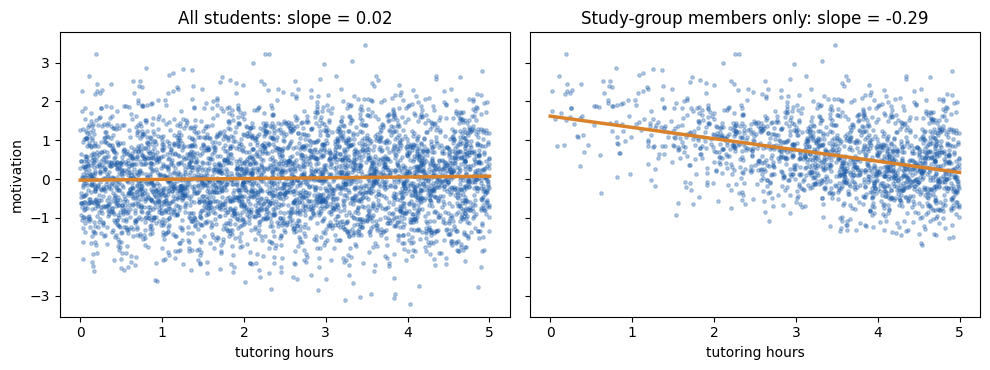

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, df, title in [(axes[0], pilot, "All students"),
                      (axes[1], pilot[pilot["study_group"] == 1], "Study-group members only")]:
    fit = ols("motivation ~ tutoring_hours", data=df).fit()
    slope = fit.params["tutoring_hours"]
    ax.scatter(df["tutoring_hours"], df["motivation"], s=6, alpha=0.3, color=BLUE)
    xs = np.linspace(0, 5, 2)
    ax.plot(xs, fit.params["Intercept"] + slope * xs, color=ORANGE, lw=2.5)
    ax.set_title(f"{title}: slope = {slope:.2f}")
    ax.set_xlabel("tutoring hours")
axes[0].set_ylabel("motivation")
plt.tight_layout()
plt.show()

**Answers**

1. **No.** Hours came from a lottery (flat line, left).
2. Not because of tutoring (they had little), so they must be **motivated**.
3. Motivation goes **down** as hours go up (right): hours and motivation now look negatively related.

- Study group has two arrows in → it is a **collider**
- Looking within its groups (filtering *or* adding it as a control) creates a link between its causes

### Discussion

Recall: among members, more hours ↔ less motivation, and motivation raises scores.

1. What happens to the slope of score on hours if we control for study group?
2. We have measured motivation. Can we undo the damage?

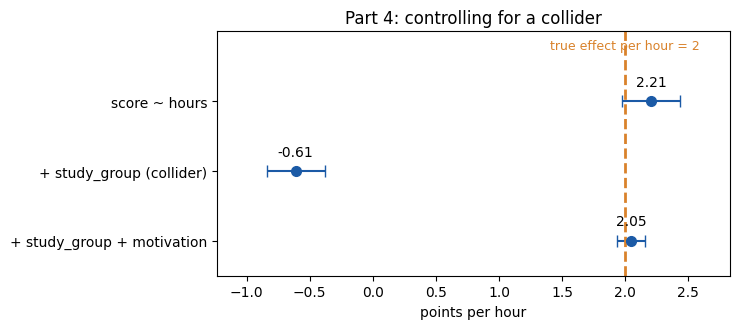

In [15]:
models = {
    "score ~ hours": "exam_score ~ tutoring_hours",
    "+ study_group (collider)": "exam_score ~ tutoring_hours + study_group",
    "+ study_group + motivation": "exam_score ~ tutoring_hours + study_group + motivation",
}
fits = {label: ols(f, data=pilot).fit() for label, f in models.items()}

coef_plot([(label, *ci(m, "tutoring_hours")) for label, m in fits.items()],
          {"true effect per hour": 2}, "Part 4: controlling for a collider", xlabel="points per hour")

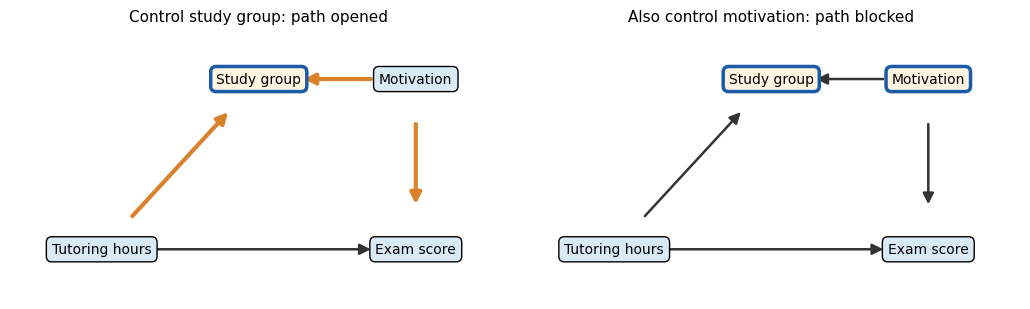

In [16]:
draw_dags([dict(title="Control study group: path opened", edges=PILOT_EDGES, pos=POS4,
                boxed={"Study group"},
                highlight={("Tutoring hours", "Study group"), ("Motivation", "Study group"),
                           ("Motivation", "Exam score")}),
           dict(title="Also control motivation: path blocked", edges=PILOT_EDGES, pos=POS4,
                boxed={"Study group", "Motivation"})])

**Answers**

1. The slope gets pulled **down**, here all the way below zero: tutoring looks *harmful*
    - Controlling for study group opens hours → study group ← motivation → score (left diagram)
2. **Yes.** Controlling for motivation blocks that path (right diagram) → back to ≈ 2

- **score ~ hours** was already correct: the lottery means there's nothing to block
- **+ study_group + motivation** is correct again, and has the narrowest interval

**Takeaways**

- Don't control for a collider
- If you already have, controlling for its **other cause** can repair it, but only if that cause is measured
- Slides' report example: the other cause of inclusion was the **score itself**. You can't control for the outcome → no repair, you need the full data.

---
## Part 5: Diagrams and equations are not one-to-one

### One diagram → many equations (recap of Part 3)

Take this diagram (the lottery school from Part 3):

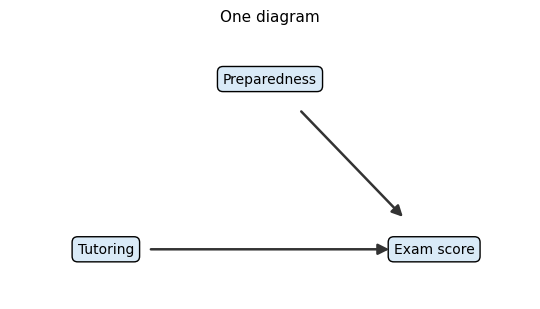

In [17]:
draw_dags([dict(title="One diagram", pos=POS3,
                edges=[("Preparedness", "Exam score"), ("Tutoring", "Exam score")])],
          figsize=(5.5, 3.2))

All of these score equations produce it (T = tutoring, P = preparedness):

| Score equation | Effect of tutoring |
|---|---|
| $70 + 4T + 6P$ | 4 for everyone |
| $70 + (4 - 2P)T + 6P$ | depends on preparedness |
| $70 + 4T + 6P + 3P^2$ | 4 for everyone; curved in preparedness |

- The diagram can't tell these apart

### One equation → many diagrams

Now fix **one** score equation:

$$\text{score} = 70 + 4\cdot\text{tutoring hours} + 3\cdot\text{confidence} + \text{noise}$$

- `confidence`: measured mid-term
- Three worlds. Same score equation. Different link between tutoring hours and confidence.

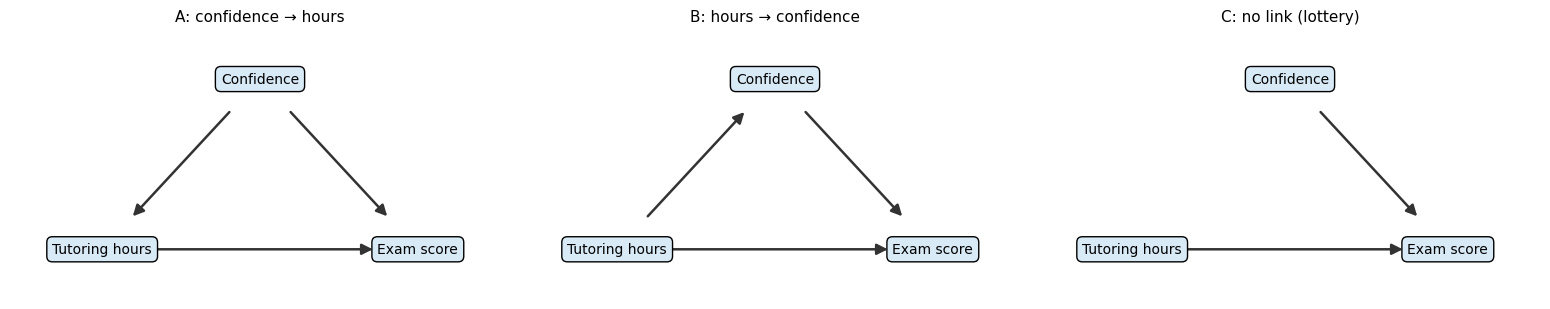

In [18]:
POS5 = {"Tutoring hours": (0, 0), "Exam score": (2, 0), "Confidence": (1, 1.4)}
into_score = [("Tutoring hours", "Exam score"), ("Confidence", "Exam score")]
draw_dags([dict(title="A: confidence → hours", pos=POS5, edges=into_score + [("Confidence", "Tutoring hours")]),
           dict(title="B: hours → confidence", pos=POS5, edges=into_score + [("Tutoring hours", "Confidence")]),
           dict(title="C: no link (lottery)", pos=POS5, edges=into_score)])

In [19]:
rng = np.random.default_rng(2028)

conf_a = rng.normal(0, 1, n)
hours_a = 2.5 + 0.8 * conf_a + rng.normal(0, 1, n)            # confident students take more hours
world_a = pd.DataFrame({"tutoring_hours": hours_a, "confidence": conf_a})

hours_b = rng.uniform(0, 5, n)
conf_b = 1.0 * (hours_b - 2.5) + rng.normal(0, 1, n)          # tutoring builds confidence
world_b = pd.DataFrame({"tutoring_hours": hours_b, "confidence": conf_b})

hours_c = rng.uniform(0, 5, n)
conf_c = rng.normal(0, 1, n)
world_c = pd.DataFrame({"tutoring_hours": hours_c, "confidence": conf_c})

for world in (world_a, world_b, world_c):                      # the same score equation everywhere
    world["exam_score"] = 70 + 4 * world["tutoring_hours"] + 3 * world["confidence"] + rng.normal(0, 4, n)

### Discussion

For each world:

1. Follow the arrows **out of** tutoring hours. Does any path to score go through confidence?
2. What is the **total** effect of one extra hour?
3. Should we control for confidence?

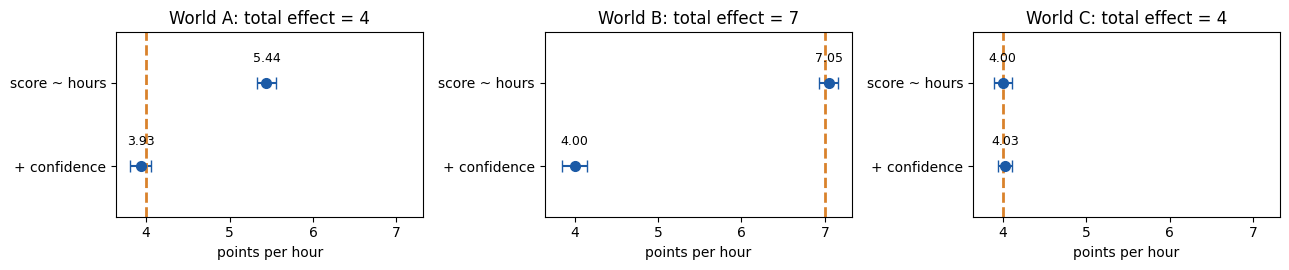

In [20]:
truth = {"A": 4, "B": 4 + 3 * 1.0, "C": 4}
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8), sharex=True)
for ax, (name, world) in zip(axes, [("A", world_a), ("B", world_b), ("C", world_c)]):
    rows = [(label, *ci(ols(f, data=world).fit(), "tutoring_hours"))
            for label, f in [("score ~ hours", "exam_score ~ tutoring_hours"),
                             ("+ confidence", "exam_score ~ tutoring_hours + confidence")]]
    for i, (label, est, lo, hi) in enumerate(rows):
        ax.errorbar(est, i, xerr=[[est - lo], [hi - est]], fmt="o", color=BLUE, capsize=4, ms=7)
        ax.text(est, i - 0.25, f"{est:.2f}", ha="center", fontsize=9)
    ax.axvline(truth[name], color=ORANGE, ls="--", lw=2)
    ax.set_yticks([0, 1], [r[0] for r in rows])
    ax.set_ylim(1.6, -0.6)
    ax.set_title(f"World {name}: total effect = {truth[name]:g}")
    ax.set_xlabel("points per hour")
plt.tight_layout()
plt.show()

**Answers**

| World | Q1: path through confidence? | Q2: total effect | Confidence is a... | Q3: control for it? |
|---|---|---|---|---|
| A | no (arrow points *into* hours) | 4 | confounder | **yes** |
| B | yes: hours → confidence → score | 4 + 1 × 3 = **7** | mediator | **no** (for the total effect) |
| C | no | 4 | unrelated cause | optional (narrower interval) |

- `+ confidence` gives ≈ 4 in **every** world. It always matches the equation's coefficient.
- But 4 is the *total* effect only in A and C
- **The equation doesn't tell you what to control for. The diagram does.**
- The data can't separate A from B either: in both, hours and confidence just move together
- What decides it: **timing and domain knowledge** (was confidence measured before or after tutoring began?)

---
## Wrap-up: what comparison did we create?

| Analysis | Comparison | Tells us |
|---|---|---|
| Control preparedness (school's diagram) | similar preparedness | total effect, even without practice in the diagram |
| + practice | same preparedness **and** practice | only the part not through practice |
| + practice, forget preparedness | same practice | biased: backdoor + collider path open |
| Simple model, lottery + interaction | all vs all | average effect, not how it varies |
| Interaction, averaged | effect at each preparedness level | average effect, in both schools |
| + study group (collider) | same study-group status | biased, even the wrong sign |
| + study group + motivation | same status and motivation | correct again |
| + confidence | same confidence | total effect only if confidence isn't a mediator |

**Exit question:** before trusting a coefficient, what must you decide besides which regression to run?

- Which effect? (total or direct; for whom)
- The assumed diagram
- What to control for, and which rows to keep
- The equation's form (interactions, curves)